In [11]:
import time 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import StandardScaler 
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import ( roc_auc_score, classification_report, RocCurveDisplay ) 
from sklearn.model_selection import ( cross_val_score, StratifiedKFold, cross_val_predict )
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [12]:
# Load the clustered dataset

data_clustered = pd.read_csv(
    "../data/processed/vehicle_co2_technology_clusters.csv"
)

print("Dataset shape:", data_clustered.shape)
print("\nColumns:") 
print(data_clustered.columns.tolist())

Dataset shape: (5985, 15)

Columns:
['make', 'model', 'vehicle_class', 'engine_size', 'cylinders', 'transmission', 'fuel_type', 'co2', 'transmission_gears', 'transmission_type', 'engine_per_cylinder', 'engine_x_cylinders', 'engine_size_sq', 'cylinders_sq', 'technology_cluster']


In [13]:
# BASIC DATA CHECK

print("Columns:")
print(data_clustered.columns.tolist())

print("\nDataset shape:")
print(data_clustered.shape)

print("\nMissing values:")
print(data_clustered.isnull().sum())

Columns:
['make', 'model', 'vehicle_class', 'engine_size', 'cylinders', 'transmission', 'fuel_type', 'co2', 'transmission_gears', 'transmission_type', 'engine_per_cylinder', 'engine_x_cylinders', 'engine_size_sq', 'cylinders_sq', 'technology_cluster']

Dataset shape:
(5985, 15)

Missing values:
make                   0
model                  0
vehicle_class          0
engine_size            0
cylinders              0
transmission           0
fuel_type              0
co2                    0
transmission_gears     0
transmission_type      0
engine_per_cylinder    0
engine_x_cylinders     0
engine_size_sq         0
cylinders_sq           0
technology_cluster     0
dtype: int64


In [14]:
print("\nNumber of technology clusters:") 
print(data_clustered["technology_cluster"].nunique()) 
print("\nCluster counts:") 
print( data_clustered["technology_cluster"] .value_counts() .sort_index() )


Number of technology clusters:
8

Cluster counts:
technology_cluster
0     583
1    2154
2     589
3     930
4     781
5     139
6     474
7     335
Name: count, dtype: int64


In [15]:
# PROFILE ALL TECHNOLOGY CLUSTERS
cluster_profile = (
    data_clustered .groupby("technology_cluster") 
    .agg( 
        count=("technology_cluster", "size"), 
        mean_engine_size=("engine_size", "mean"), 
        mean_cylinders=("cylinders", "mean"), 
        mean_transmission_gears=("transmission_gears", "mean") 
        ) .round(3) 
    )
print("ALL TECHNOLOGY CLUSTER PROFILES")
print( cluster_profile.to_string() )

ALL TECHNOLOGY CLUSTER PROFILES
                    count  mean_engine_size  mean_cylinders  mean_transmission_gears
technology_cluster                                                                  
0                     583             2.060           3.981                    8.333
1                    2154             1.973           3.976                    5.991
2                     589             5.044           8.088                    7.626
3                     930             3.256           5.994                    7.624
4                     781             3.504           6.000                    5.919
5                     139             6.399          11.986                    7.583
6                     474             5.370           8.030                    5.819
7                     335             3.851           6.663                    9.472


In [16]:
# CALCULATE TECHNOLOGY SCORE
# We create an engineering-based score for each cluster. 
# Direction: Engine size -> larger = older, Cylinders -> larger = older, Transmission gears -> larger = newer
# Therefore: Older technology score = + engine size + cylinders - transmission gears
# Because these variables have different scales, we standardise the cluster means before combining them.

score_features = [ 
    "mean_engine_size", 
    "mean_cylinders", 
    "mean_transmission_gears"
] 

cluster_score_data = cluster_profile[score_features].copy() 
# Standardise the three cluster-level engineering characteristics 
score_means = cluster_score_data.mean() 
score_stds = cluster_score_data.std(ddof=0) 
cluster_z = ( cluster_score_data - score_means ) / score_stds 
# Older technology: 
# larger engine -> positive 
# more cylinders -> positive 
# more gears -> negative 
cluster_profile["technology_score"] = ( cluster_z["mean_engine_size"] + cluster_z["mean_cylinders"] - cluster_z["mean_transmission_gears"] ) 
cluster_profile["technology_score"] = ( cluster_profile["technology_score"] .round(4) )

In [17]:
# RANK ALL CLUSTERS FROM OLDER TO NEWER
cluster_ranking = ( 
    cluster_profile .sort_values( 
        "technology_score", ascending=False 
        ) .copy() 
    ) 
cluster_ranking["technology_rank"] = ( np.arange(1, len(cluster_ranking) + 1) ) 
print("TECHNOLOGY CLUSTER RANKING")
print( 
    cluster_ranking[ 
        [ "count", "mean_engine_size", "mean_cylinders", "mean_transmission_gears", "technology_score", "technology_rank" ] 
    ].to_string() 
) 
print("\nInterpretation:") 
print("Rank 1 = oldest technology group") 
print( f"Rank {len(cluster_ranking)} = newest technology group" )

TECHNOLOGY CLUSTER RANKING
                    count  mean_engine_size  mean_cylinders  mean_transmission_gears  technology_score  technology_rank
technology_cluster                                                                                                     
5                     139             6.399          11.986                    7.583            3.5550                1
6                     474             5.370           8.030                    5.819            2.6766                2
2                     589             5.044           8.088                    7.626            0.9970                3
4                     781             3.504           6.000                    5.919            0.4935                4
3                     930             3.256           5.994                    7.624           -1.0758                5
1                    2154             1.973           3.976                    5.991           -1.4368                6
7            

In [18]:
# %%
# CHECK CANDIDATE TECHNOLOGY-SHIFT SPLITS
#
# We test possible boundaries between older and newer
# technology clusters.
#
# The split is NOT selected using model R2.
# We only inspect the distribution characteristics.

candidate_boundaries = [3, 4, 5, 6]

split_results = []

for boundary in candidate_boundaries:

    # Older technology clusters
    old_clusters = cluster_ranking[
        cluster_ranking["technology_rank"] <= boundary
    ].index.tolist()

    # Newer technology clusters
    new_clusters = cluster_ranking[
        cluster_ranking["technology_rank"] > boundary
    ].index.tolist()

    # Create the two groups
    old_data = data_clustered[
        data_clustered["technology_cluster"].isin(old_clusters)
    ].copy()

    new_data = data_clustered[
        data_clustered["technology_cluster"].isin(new_clusters)
    ].copy()

    # Training engine-size range
    old_min_engine = old_data["engine_size"].min()
    old_max_engine = old_data["engine_size"].max()

    # Test observations outside training engine-size range
    outside_engine_range = (
        (new_data["engine_size"] < old_min_engine) |
        (new_data["engine_size"] > old_max_engine)
    )

    outside_percentage = (
        outside_engine_range.mean() * 100
    )

    # Store results
    split_results.append({
        "boundary": boundary,
        "old_clusters": str(old_clusters),
        "new_clusters": str(new_clusters),
        "S_old_size": len(old_data),
        "S_new_size": len(new_data),
        "S_old_mean_engine": old_data["engine_size"].mean(),
        "S_new_mean_engine": new_data["engine_size"].mean(),
        "S_old_mean_cylinders": old_data["cylinders"].mean(),
        "S_new_mean_cylinders": new_data["cylinders"].mean(),
        "OOD_engine_range_percent": outside_percentage
    })


split_comparison = pd.DataFrame(split_results)

print("\n" + "=" * 80)
print("CANDIDATE TECHNOLOGY-SHIFT SPLITS")
print("=" * 80)

print(
    split_comparison[
        [
            "boundary",
            "S_old_size",
            "S_new_size",
            "S_old_mean_engine",
            "S_new_mean_engine",
            "S_old_mean_cylinders",
            "S_new_mean_cylinders",
            "OOD_engine_range_percent"
        ]
    ].round(3).to_string(index=False)
)


CANDIDATE TECHNOLOGY-SHIFT SPLITS
 boundary  S_old_size  S_new_size  S_old_mean_engine  S_new_mean_engine  S_old_mean_cylinders  S_new_mean_cylinders  OOD_engine_range_percent
        3        1202        4783              5.329              2.615                 8.516                 4.888                    94.020
        4        1983        4002              4.610              2.441                 7.525                 4.671                    58.621
        5        2913        3072              4.178              2.194                 7.036                 4.270                    76.367
        6        5067         918              3.241              2.714                 5.735                 4.960                     0.000


In [19]:
for boundary in [4, 5]:

    old_clusters = cluster_ranking[
        cluster_ranking["technology_rank"] <= boundary
    ].index.tolist()

    new_clusters = cluster_ranking[
        cluster_ranking["technology_rank"] > boundary
    ].index.tolist()

    old_data = data_clustered[
        data_clustered["technology_cluster"].isin(old_clusters)
    ].copy()

    new_data = data_clustered[
        data_clustered["technology_cluster"].isin(new_clusters)
    ].copy()

    print("\n" + "=" * 70)
    print(f"BOUNDARY {boundary}")
    print("=" * 70)

    print("S_old clusters:", old_clusters)
    print("S_new clusters:", new_clusters)

    print("\nDataset size")
    print("S_old:", len(old_data))
    print("S_new:", len(new_data))

    print("\nEngine size")
    print(
        "S_old:",
        round(old_data["engine_size"].mean(), 3),
        "mean | range:",
        old_data["engine_size"].min(),
        "-",
        old_data["engine_size"].max()
    )

    print(
        "S_new:",
        round(new_data["engine_size"].mean(), 3),
        "mean | range:",
        new_data["engine_size"].min(),
        "-",
        new_data["engine_size"].max()
    )

    print("\nCylinders")
    print(
        "S_old:",
        round(old_data["cylinders"].mean(), 3),
        "mean | range:",
        old_data["cylinders"].min(),
        "-",
        old_data["cylinders"].max()
    )

    print(
        "S_new:",
        round(new_data["cylinders"].mean(), 3),
        "mean | range:",
        new_data["cylinders"].min(),
        "-",
        new_data["cylinders"].max()
    )

    print("\nCO2")
    print(
        "S_old:",
        round(old_data["co2"].mean(), 3),
        "mean | median:",
        round(old_data["co2"].median(), 3)
    )

    print(
        "S_new:",
        round(new_data["co2"].mean(), 3),
        "mean | median:",
        round(new_data["co2"].median(), 3)
    )

    # Engine-size OOD
    old_min = old_data["engine_size"].min()
    old_max = old_data["engine_size"].max()

    ood_mask = (
        (new_data["engine_size"] < old_min) |
        (new_data["engine_size"] > old_max)
    )

    print(
        "\nEngine-size OOD:",
        int(ood_mask.sum()),
        "/",
        len(new_data),
        "=",
        round(ood_mask.mean() * 100, 2),
        "%"
    )


BOUNDARY 4
S_old clusters: [5, 6, 2, 4]
S_new clusters: [3, 1, 7, 0]

Dataset size
S_old: 1983
S_new: 4002

Engine size
S_old: 4.61 mean | range: 2.5 - 8.4
S_new: 2.441 mean | range: 0.9 - 6.2

Cylinders
S_old: 7.525 mean | range: 6 - 16
S_new: 4.671 mean | range: 3 - 8

CO2
S_old: 308.311 mean | median: 302.0
S_new: 222.48 mean | median: 221.0

Engine-size OOD: 2346 / 4002 = 58.62 %

BOUNDARY 5
S_old clusters: [5, 6, 2, 4, 3]
S_new clusters: [1, 7, 0]

Dataset size
S_old: 2913
S_new: 3072

Engine size
S_old: 4.178 mean | range: 2.5 - 8.4
S_new: 2.194 mean | range: 0.9 - 6.2

Cylinders
S_old: 7.036 mean | range: 5 - 16
S_new: 4.27 mean | range: 3 - 8

CO2
S_old: 291.457 mean | median: 285.0
S_new: 212.478 mean | median: 209.0

Engine-size OOD: 2346 / 3072 = 76.37 %


In [20]:
# DIVIDE ALL CLUSTERS INTO OLDER AND NEWER GROUPS
# With 8 clusters: 
# Older = first 4 clusters
# Newer = last 4 clusters
# This is an operational choice for converting the 8-cluster solution into
# the binary S_old / S_new temporal groups required for temporal evaluation.

number_of_clusters = len(cluster_ranking)
if number_of_clusters < 2:
    raise ValueError("At least two technology clusters are required.")
if number_of_clusters % 2 != 0:
    raise ValueError("The number of clusters is odd. " "Please define an explicit boundary between older and newer groups.")
number_per_group = number_of_clusters // 2
older_clusters = (cluster_ranking.head(number_per_group).index.tolist())
newer_clusters = (cluster_ranking.tail(number_per_group).index.tolist())
print("OLDER / NEWER TECHNOLOGY GROUPS")
print(f"\nOlder clusters ({len(older_clusters)}): {older_clusters}")
print(f"Newer clusters ({len(newer_clusters)}): {newer_clusters}")

OLDER / NEWER TECHNOLOGY GROUPS

Older clusters (4): [5, 6, 2, 4]
Newer clusters (4): [3, 1, 7, 0]


In [21]:
# ADD TEMPORAL GROUP LABEL

data_adv = data_clustered.copy()
data_adv["technology_group"] = np.where(
    data_adv["technology_cluster"].isin(older_clusters), "S_old", "S_new"
)
print("TEMPORAL GROUP COUNTS")
print(data_adv["technology_group"].value_counts())

TEMPORAL GROUP COUNTS
technology_group
S_new    4002
S_old    1983
Name: count, dtype: int64


In [22]:
# CREATE S_old AND S_new
S_old = data_adv[ data_adv["technology_group"] == "S_old" ].copy() 
S_new = data_adv[ data_adv["technology_group"] == "S_new" ].copy() 
print("\nS_old observations:", len(S_old)) 
print("S_new observations:", len(S_new)) 
print("\nS_old clusters:") 
print( sorted(S_old["technology_cluster"].unique()) ) 
print("\nS_new clusters:") 
print( sorted(S_new["technology_cluster"].unique()) ) 


S_old observations: 1983
S_new observations: 4002

S_old clusters:
[np.int64(2), np.int64(4), np.int64(5), np.int64(6)]

S_new clusters:
[np.int64(0), np.int64(1), np.int64(3), np.int64(7)]


In [23]:
# CREATE ADVERSARIAL DATASET
# Binary labels: 0 = S_old, 1 = S_new
# The classifier will try to distinguish older from newer technology observations.

S_old["adv_label"] = 0
S_new["adv_label"] = 1
adv_data = pd.concat([S_old, S_new], ignore_index=True)
print("\n" + "=" * 70)
print("ADVERSARIAL DATASET")
print("=" * 70)
print(f"\nTotal observations: {len(adv_data)}")
print("\nLabel distribution:")
print(adv_data["adv_label"].value_counts().sort_index())


ADVERSARIAL DATASET

Total observations: 5985

Label distribution:
adv_label
0    1983
1    4002
Name: count, dtype: int64


In [24]:
# LEAKAGE-FREE ADVERSARIAL FEATURS
numeric_features = [
    "engine_size",
    "cylinders",
    "engine_per_cylinder",
    "engine_x_cylinders",
    "engine_size_sq",
    "cylinders_sq"
]

categorical_features = [
    "make",
    "vehicle_class",
    "transmission_type",
    "fuel_type",
    "model"
]

required_features = numeric_features + categorical_features

missing_features = [
    feature for feature in required_features
    if feature not in adv_data.columns
]

if missing_features:
    raise ValueError(
        f"Missing required features: {missing_features}"
    )

print("ADVERSARIAL FEATURES")

print("\nNumeric:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

ADVERSARIAL FEATURES

Numeric:
['engine_size', 'cylinders', 'engine_per_cylinder', 'engine_x_cylinders', 'engine_size_sq', 'cylinders_sq']

Categorical:
['make', 'vehicle_class', 'transmission_type', 'fuel_type', 'model']


In [25]:
# PREPARE ADVERSARIAL DATA

X_adv = adv_data[required_features].copy()
y_adv = adv_data["adv_label"].copy()

print("ADVERSARIAL DATA")
print(f"\nFeature matrix shape: {X_adv.shape}")
print(f"Number of observations: {len(X_adv)}")
print(f"Number of labels: {y_adv.nunique()}")

ADVERSARIAL DATA

Feature matrix shape: (5985, 11)
Number of observations: 5985
Number of labels: 2


In [26]:
# PREPROCESSING + LOGISTIC REGRESSION PIPELINE

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

adversarial_pipeline = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            solver="lbfgs",
            random_state=42
        )
    )
])

In [27]:
# 5-FOLD CROSS-VALIDATED ADVERSARIAL VALIDATION
cv = StratifiedKFold( n_splits=5, shuffle=True, random_state=42 ) 
start_time = time.time() 
cv_auc_scores = cross_val_score( adversarial_pipeline, X_adv, y_adv, cv=cv, scoring="roc_auc" ) 
training_time = time.time() - start_time 
auc_mean = cv_auc_scores.mean() 
auc_std = cv_auc_scores.std() 
print("ADVERSARIAL VALIDATION RESULTS") 
print( "\n5-fold ROC-AUC scores:" )
print( np.round(cv_auc_scores, 4) )
print( f"\nMean ROC-AUC: {auc_mean:.4f}" ) 
print( f"ROC-AUC Std: {auc_std:.4f}" ) 
print( f"Training time: {training_time:.4f} seconds" )

ADVERSARIAL VALIDATION RESULTS

5-fold ROC-AUC scores:
[0.9839 0.978  0.9814 0.9784 0.9761]

Mean ROC-AUC: 0.9796
ROC-AUC Std: 0.0027
Training time: 0.7462 seconds


In [28]:
# DRIFT VERDICT
# Proposal threshold: 
# AUC >= 0.60 -> measurable distribution shift 
# AUC < 0.60 -> insufficient evidence of measurable shift

DRIFT_THRESHOLD = 0.60 
if auc_mean >= DRIFT_THRESHOLD: 
    verdict = ( "Measurable distribution shift detected." ) 
    proceed = True 
else: 
    verdict = ( "Insufficient evidence of measurable distribution shift." ) 
    proceed = False 
print("DRIFT VERDICT")
print( f"\nMean ROC-AUC: {auc_mean:.4f}" ) 
print( f"Threshold: {DRIFT_THRESHOLD:.2f}" ) 
print( f"Verdict: {verdict}" ) 
print( f"Proceed with temporal evaluation: {proceed}" )

DRIFT VERDICT

Mean ROC-AUC: 0.9796
Threshold: 0.60
Verdict: Measurable distribution shift detected.
Proceed with temporal evaluation: True


In [29]:
# CROSS-VALIDATED PREDICTIONS
# Generate out-of-fold probabilities for the ROC curve.
y_adv_proba_cv = cross_val_predict(
    adversarial_pipeline,
    X_adv,
    y_adv,
    cv=cv,
    method="predict_proba"
)[:, 1] 
cv_auc_out_of_fold = roc_auc_score( y_adv, y_adv_proba_cv ) 
print("OUT-OF-FOLD ROC-AUC") 
print( f"\nOut-of-fold ROC-AUC: " f"{cv_auc_out_of_fold:.4f}" )

OUT-OF-FOLD ROC-AUC

Out-of-fold ROC-AUC: 0.9794


In [30]:
# CROSS-VALIDATED CLASSIFICATION REPORT
y_adv_pred_cv = ( y_adv_proba_cv >= 0.50 ).astype(int) 
print("CLASSIFICATION REPORT") 
print( classification_report( y_adv, y_adv_pred_cv, target_names=[ "S_old", "S_new" ], zero_division=0 ) )

CLASSIFICATION REPORT
              precision    recall  f1-score   support

       S_old       0.89      0.92      0.90      1983
       S_new       0.96      0.94      0.95      4002

    accuracy                           0.94      5985
   macro avg       0.92      0.93      0.93      5985
weighted avg       0.94      0.94      0.94      5985



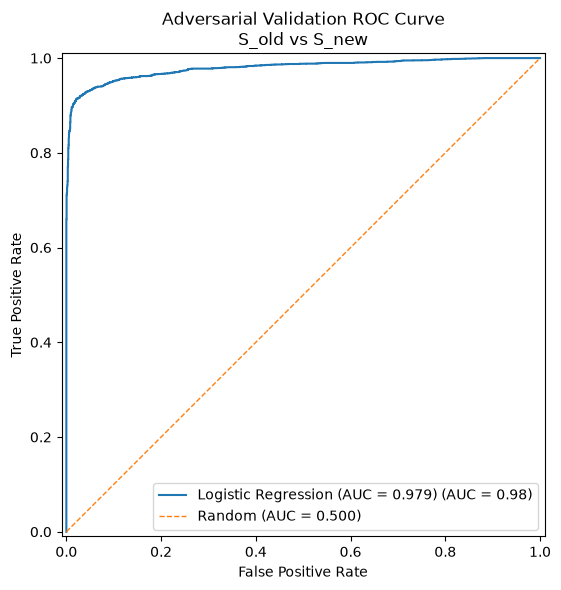

In [31]:
# ROC CURVE
fig, ax = plt.subplots( figsize=(8, 6) ) 
RocCurveDisplay.from_predictions( y_adv, y_adv_proba_cv, name=f"Logistic Regression (AUC = {cv_auc_out_of_fold:.3f})", ax=ax ) 
ax.plot( [0, 1], [0, 1], linestyle="--", linewidth=1, label="Random (AUC = 0.500)" ) 
ax.set_xlabel( "False Positive Rate" ) 
ax.set_ylabel( "True Positive Rate" ) 
ax.set_title( "Adversarial Validation ROC Curve\n" "S_old vs S_new" ) 
ax.legend( loc="lower right" ) 
plt.tight_layout() 
plt.savefig( "../results/figures/adversarial_validation_roc_curve.pdf", format="pdf", bbox_inches="tight" ) 
plt.show() 
plt.close()

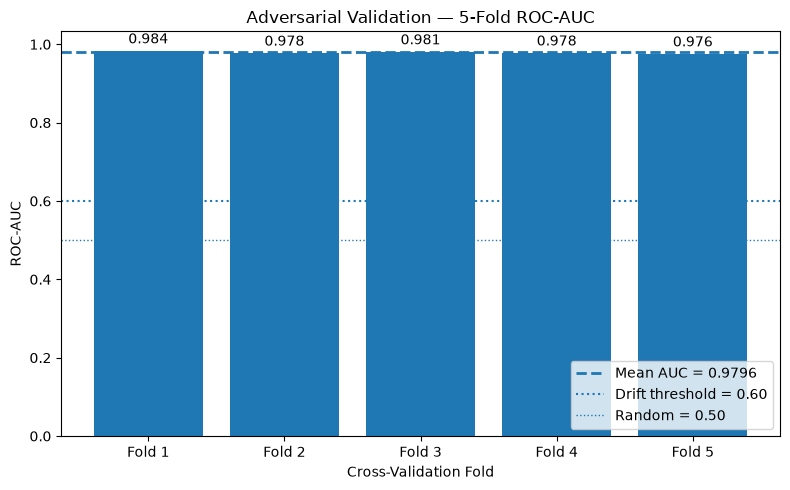

In [32]:
# CROSS-VALIDATION AUC PLOT
fig, ax = plt.subplots( figsize=(8, 5) ) 
fold_labels = [ f"Fold {i + 1}" for i in range(len(cv_auc_scores)) ] 
bars = ax.bar( fold_labels, cv_auc_scores ) 
ax.axhline( auc_mean, linestyle="--", linewidth=2, label=f"Mean AUC = {auc_mean:.4f}" ) 
ax.axhline( DRIFT_THRESHOLD, linestyle=":", linewidth=1.5, label="Drift threshold = 0.60" ) 
ax.axhline( 0.50, linestyle=":", linewidth=1, label="Random = 0.50" ) 
for bar, score in zip( bars, cv_auc_scores ): ax.text( bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01, f"{score:.3f}", ha="center", va="bottom" ) 
ax.set_xlabel( "Cross-Validation Fold" ) 
ax.set_ylabel( "ROC-AUC" ) 
ax.set_title( "Adversarial Validation — 5-Fold ROC-AUC" ) 
ax.legend( loc="lower right" ) 
plt.tight_layout() 
plt.savefig( "../results/figures/adversarial_validation_cv_auc.pdf", format="pdf", bbox_inches="tight" ) 
plt.show() 
plt.close()

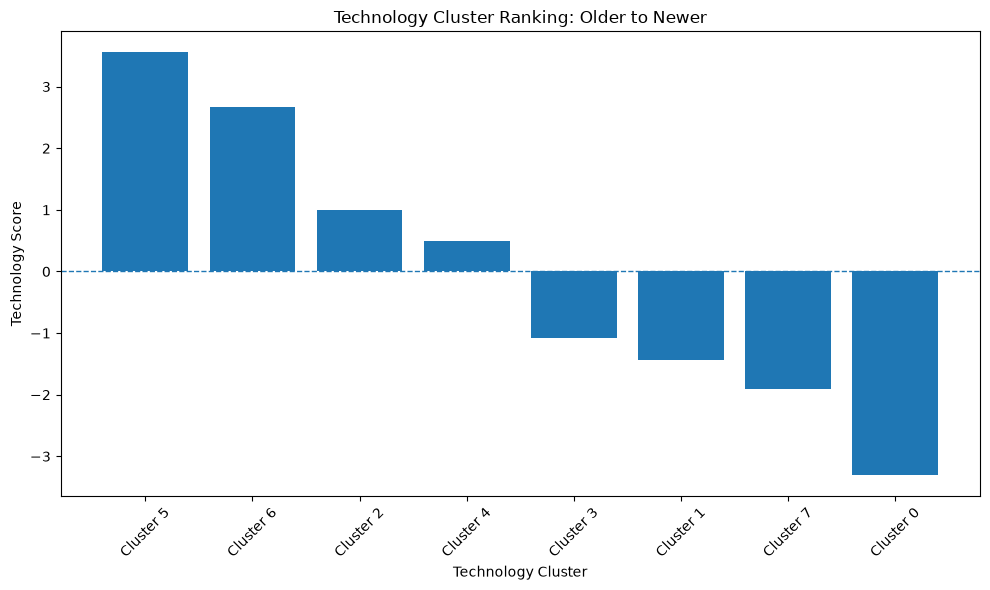

In [33]:
# TECHNOLOGY RANKING PLOT
# This shows how the eight clusters were ordered from older to newer.

plot_ranking = cluster_ranking.sort_values( "technology_rank" ) 
labels = [ f"Cluster {cluster}" for cluster in plot_ranking.index ] 
fig, ax = plt.subplots( figsize=(10, 6) ) 
bars = ax.bar( labels, plot_ranking["technology_score"] ) 
ax.axhline( 0, linestyle="--", linewidth=1 ) 
ax.set_xlabel( "Technology Cluster" ) 
ax.set_ylabel( "Technology Score" ) 
ax.set_title( "Technology Cluster Ranking: Older to Newer" ) 
plt.xticks( rotation=45 ) 
plt.tight_layout() 
plt.savefig( "../results/figures/technology_cluster_ordering.pdf", format="pdf", bbox_inches="tight" ) 
plt.show() 
plt.close()

In [34]:
# COMPARE S_old AND S_new
comparison = ( 
    data_adv 
    .groupby("technology_group") 
    .agg( 
        count=("technology_group", "size"), 
        mean_engine_size=("engine_size", "mean"), 
        mean_cylinders=("cylinders", "mean"), 
        mean_transmission_gears=("transmission_gears", "mean"), 
        mean_co2=("co2", "mean") ) 
        .round(3) 
    ) 
print("S_old vs S_new COMPARISON") 
print( comparison.to_string() )

S_old vs S_new COMPARISON
                  count  mean_engine_size  mean_cylinders  mean_transmission_gears  mean_co2
technology_group                                                                            
S_new              4002             2.441           4.671                    7.003   222.480
S_old              1983             4.610           7.525                    6.519   308.311


In [35]:
# Print final decision

# SAVE TEMPORAL TRAINING AND TESTING DATA 
S_old_final = data_adv[ data_adv["technology_group"] == "S_old" ].copy() 
S_new_final = data_adv[ data_adv["technology_group"] == "S_new" ].copy() 
# Remove the temporary adversarial label before saving 
temporary_columns = [ "adv_label", "technology_group" ] 
S_old_final.drop( columns=temporary_columns, errors="ignore", inplace=True ) 
S_new_final.drop( columns=temporary_columns, errors="ignore", inplace=True )
# Save older technology group 
S_old_final.to_csv( "../data/processed/S_old_temporal_train.csv", index=False ) 
# Save newer technology group 
S_new_final.to_csv( "../data/processed/S_new_temporal_test.csv", index=False ) 
# Save technology group 
data_adv.to_csv( "../data/processed/temporal_clusters.csv", index=False ) 
print("TEMPORAL DATASETS SAVED") 
print( f"\nS_old observations: {len(S_old_final)}" ) 
print( f"S_new observations: {len(S_new_final)}" ) 
print( "\nS_old clusters:" ) 
print( sorted( S_old_final["technology_cluster"].unique() ) ) 
print( "\nS_new clusters:" ) 
print( sorted( S_new_final["technology_cluster"].unique() ) ) 
print( "\nFiles saved successfully." )

# SAVE CLUSTER RANKING 
cluster_ranking.to_csv( "../results/tables/technology_cluster_ordering.csv" ) 
print( "\nTechnology cluster ordering saved." )

# SAVE ADVERSARIAL VALIDATION SUMMARY 
summary = pd.DataFrame({ "Metric": 
                        [ 
                            "Number_of_Clusters", 
                            "Older_Clusters", 
                            "Newer_Clusters", 
                            "S_old_Size", 
                            "S_new_Size", 
                            "AUC_CV_Mean", 
                            "AUC_CV_Std", 
                            "AUC_Out_of_Fold", 
                            "Drift_Threshold", 
                            "Drift_Verdict", 
                            "Proceed", 
                            "Training_Time_Seconds" 
                        ], 
                        "Value": [ 
                            number_of_clusters, 
                            str(older_clusters), 
                            str(newer_clusters), 
                            len(S_old_final), 
                            len(S_new_final), 
                            round(auc_mean, 4), 
                            round(auc_std, 4), 
                            round(cv_auc_out_of_fold, 4), 
                            DRIFT_THRESHOLD, 
                            verdict, 
                            proceed, 
                            round(training_time, 4) 
                            ] 
                        }) 
summary.to_csv( "../results/tables/adversarial_validation_summary.csv", index=False ) 
print("FINAL ADVERSARIAL VALIDATION SUMMARY") 
print( summary.to_string(index=False) ) 
print( "\nAll adversarial-validation results saved successfully." )

TEMPORAL DATASETS SAVED

S_old observations: 1983
S_new observations: 4002

S_old clusters:
[np.int64(2), np.int64(4), np.int64(5), np.int64(6)]

S_new clusters:
[np.int64(0), np.int64(1), np.int64(3), np.int64(7)]

Files saved successfully.

Technology cluster ordering saved.
FINAL ADVERSARIAL VALIDATION SUMMARY
               Metric                                   Value
   Number_of_Clusters                                       8
       Older_Clusters                            [5, 6, 2, 4]
       Newer_Clusters                            [3, 1, 7, 0]
           S_old_Size                                    1983
           S_new_Size                                    4002
          AUC_CV_Mean                                  0.9796
           AUC_CV_Std                                  0.0027
      AUC_Out_of_Fold                                  0.9794
      Drift_Threshold                                     0.6
        Drift_Verdict Measurable distribution shift detected.
   